# Newsvendor, Inventory Policies, and Queueing by Simulation

**What you'll learn**

- The newsvendor model from first principles: overage vs underage cost, the critical-fractile
  derivation via marginal analysis, the closed form under normal demand — and a brute-force
  expected-profit simulation over order quantities that must (and does) reproduce the formula.
- How to turn a **quantile forecast into a decision**: the P10/P50/P90 → order-quantity
  pipeline, and the dollar cost of ordering at the median when the economics say order at P90.
- Multi-period inventory with lead time: (s, S) reorder policies, Monte Carlo simulation of
  the inventory process, and the **service-level vs holding-cost frontier** you sweep to pick
  a policy — including what the last "nine" of service actually costs.
- The textbook safety-stock formula ($z \sigma \sqrt{L}$) and two realistic ways it breaks
  (skewed demand, autocorrelated demand), demonstrated formula-vs-simulation, plus the fix.
- Queueing for operations: staffing a support team as an M/M/c system, a discrete-event
  simulation validated against the Erlang-C analytic, and THE chart — wait time exploding
  nonlinearly as utilization passes ~80%.
- A **minimal discrete-event simulator in ~15 lines of plain Python** (heap of timestamped
  callbacks) — the senior swiss-army knife for any operations question that outgrows formulas.

**Why it matters in interviews**

- "How much inventory should we order?" is a canonical case question for marketplace, retail,
  and supply-chain DS roles. The senior answer is a cost-ratio quantile, not a point forecast.
- "Why does wait time blow up when the team is 90% utilized?" separates candidates who have
  internalized $1/(1-\rho)$ from those who think capacity planning is linear.
- "The warehouse wants 99% service" is a walk-them-through-the-cost question: the frontier is
  convex and you are expected to show it, then negotiate the target.
- "When do you simulate vs solve analytically?" is a judgment question about tooling maturity —
  this notebook is one long answer to it.

Cross-references: quantile forecasting and pinball loss are built in
[../05_time_series/03_ml_forecasting_backtesting.ipynb](../05_time_series/03_ml_forecasting_backtesting.ipynb);
here we consume those quantiles and turn them into orders.

In [1]:
import heapq
import itertools
import math
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

plt.rcParams.update({
    "figure.figsize": (8.0, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.autolayout": True,
})
pd.set_option("display.precision", 4)

## 1. Newsvendor from first principles

One product, one selling period, one ordering decision before demand $D$ is known.
Order $Q$ units at cost $c$, sell at price $p$, salvage leftovers at $s < c$.

Two ways to be wrong, with **asymmetric** prices:

- **Overage** (ordered too much): each leftover unit loses $c_o = c - s$.
- **Underage** (ordered too little): each lost sale forgoes margin $c_u = p - c$.

**Marginal analysis** (the derivation interviewers want, no calculus needed): consider
ordering the $(Q\!+\!1)$-th unit. It sells only if $D > Q$, i.e. with probability $1 - F(Q)$,
earning $c_u$; otherwise it costs $c_o$. Expected marginal value:

$$ c_u \,(1 - F(Q)) - c_o\, F(Q). $$

Keep ordering while this is positive; stop where it hits zero:

$$ F(Q^*) = \frac{c_u}{c_u + c_o} \equiv \text{critical fractile (CF)}. $$

The optimal order is a **quantile of the demand distribution**, at a level set purely by the
cost ratio. Under $D \sim \mathcal{N}(\mu, \sigma^2)$: $Q^* = \mu + z^*\sigma$ with
$z^* = \Phi^{-1}(\text{CF})$, and expected profit has a closed form via the standard normal
loss function $L(z) = \varphi(z) - z(1 - \Phi(z))$:

$$ \mathbb{E}[\text{profit}(Q)] = (p - s)\,\big(\mu - \sigma L(z)\big) - (c - s)\,Q,
   \qquad z = \tfrac{Q-\mu}{\sigma}. $$

**Scenario**: a bakery's sourdough loaf. Cost \$4.00, price \$10.00, day-old salvage \$1.50.
Daily demand $\mathcal{N}(200, 40^2)$.

In [2]:
price, cost, salvage = 10.0, 4.0, 1.50
c_u = price - cost           # underage: margin lost per missed sale
c_o = cost - salvage         # overage: loss per unsold loaf
crit_fractile = c_u / (c_u + c_o)

mu_d, sigma_d = 200.0, 40.0
z_star = stats.norm.ppf(crit_fractile)
q_star = mu_d + z_star * sigma_d

print(f"underage cost c_u = ${c_u:.2f}, overage cost c_o = ${c_o:.2f}")
print(f"critical fractile  = {crit_fractile:.4f} -> z* = {z_star:.3f}")
print(f"optimal order Q*   = {q_star:.1f} loaves (mean demand is {mu_d:.0f})")

underage cost c_u = $6.00, overage cost c_o = $2.50
critical fractile  = 0.7059 -> z* = 0.541
optimal order Q*   = 221.7 loaves (mean demand is 200)


In [3]:
def newsvendor_profit_normal(q, mu, sigma, price, cost, salvage):
    """Closed-form E[profit] for normal demand, via the standard normal loss function."""
    q, mu, sigma = np.asarray(q, float), np.asarray(mu, float), np.asarray(sigma, float)
    z = (q - mu) / sigma
    loss = stats.norm.pdf(z) - z * stats.norm.sf(z)   # E[(D-Q)^+] / sigma
    expected_sales = mu - sigma * loss                # E[min(D, Q)]
    return (price - salvage) * expected_sales - (cost - salvage) * q


# Brute force: for each candidate Q, average profit over many simulated demand days.
n_draws = 100_000
demand_draws = np.maximum(rng.normal(mu_d, sigma_d, n_draws), 0.0)
q_grid = np.arange(120.0, 301.0, 2.0)

sales = np.minimum(demand_draws[None, :], q_grid[:, None])
profit_sim = (price * sales + salvage * (q_grid[:, None] - sales)
              - cost * q_grid[:, None]).mean(axis=1)
profit_formula = newsvendor_profit_normal(q_grid, mu_d, sigma_d, price, cost, salvage)

q_best_sim = q_grid[np.argmax(profit_sim)]
max_gap = np.max(np.abs(profit_sim - profit_formula))
print(f"argmax by simulation: Q = {q_best_sim:.0f}   formula Q* = {q_star:.1f}")
print(f"max |sim - formula| over the grid: ${max_gap:.2f} "
      f"(Monte Carlo noise on a ~$1,150 objective)")
assert max_gap < 10.0 and abs(q_best_sim - q_star) < 8.0  # curves must match

argmax by simulation: Q = 222   formula Q* = 221.7
max |sim - formula| over the grid: $1.68 (Monte Carlo noise on a ~$1,150 objective)


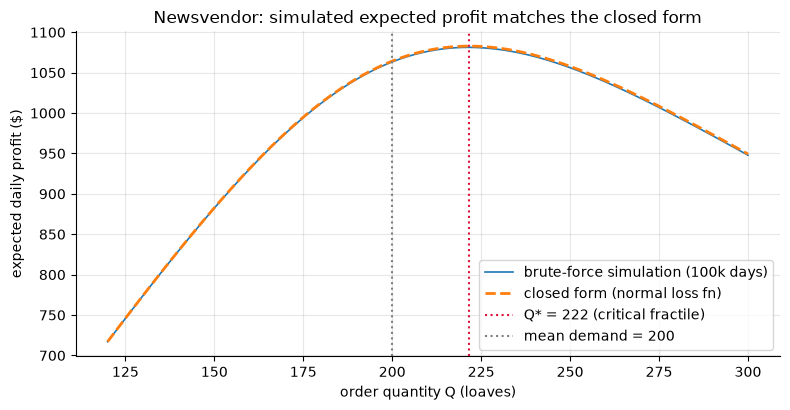

E[profit] ordering the MEAN (Q=200): $1064/day
E[profit] ordering Q*=222:          $1083/day  (+$18/day, +1.7%)


In [4]:
fig, ax = plt.subplots()
ax.plot(q_grid, profit_sim, lw=1.2, label="brute-force simulation (100k days)")
ax.plot(q_grid, profit_formula, "--", lw=2, label="closed form (normal loss fn)")
ax.axvline(q_star, color="crimson", ls=":", label=f"Q* = {q_star:.0f} (critical fractile)")
ax.axvline(mu_d, color="gray", ls=":", label=f"mean demand = {mu_d:.0f}")
ax.set_xlabel("order quantity Q (loaves)")
ax.set_ylabel("expected daily profit ($)")
ax.set_title("Newsvendor: simulated expected profit matches the closed form")
ax.legend()
plt.show()

p_at_mean = newsvendor_profit_normal(mu_d, mu_d, sigma_d, price, cost, salvage)
p_at_star = newsvendor_profit_normal(q_star, mu_d, sigma_d, price, cost, salvage)
print(f"E[profit] ordering the MEAN (Q=200): ${p_at_mean:.0f}/day")
print(f"E[profit] ordering Q*={q_star:.0f}:          ${p_at_star:.0f}/day  "
      f"(+${p_at_star - p_at_mean:.0f}/day, {(p_at_star / p_at_mean - 1):+.1%})")

Two things a senior candidate should point out on this chart:

- The optimum is **not at mean demand**. Because margin ($6) far exceeds the overage loss
  ($2.50), you deliberately over-order — CF ≈ 0.71 means you plan to have leftovers ~71% of
  days. Stockouts on 29% of days is the *optimal* amount of stocking out.
- The profit curve is **asymmetric and flat near the top**: under-ordering by 40 loaves
  costs much more than over-ordering by 40. When demand parameters are uncertain, err on the
  side the cost ratio favors — the flat top means precision in $Q$ matters less than being
  on the right side of it.

## 2. From forecasts to decisions: the P10/P50/P90 → order-quantity pipeline

In production you don't get a demand distribution — you get a **forecast**. If the forecast
system emits quantiles (as built with pinball loss in
[../05_time_series/03_ml_forecasting_backtesting.ipynb](../05_time_series/03_ml_forecasting_backtesting.ipynb)),
the newsvendor result tells you *which quantile is the decision*:

1. Compute CF from unit economics.
2. Order the CF-quantile of the demand forecast for that day/SKU. Done.

The classic failure is shipping the **point forecast** (the P50) to the ordering system,
because "that's the forecast". The median is only optimal when $c_u = c_o$ — almost never
true. Let's price the mistake.

**Scenario**: fresh berries. Cost \$3, price \$12, salvage \$2 (juice processor). So
$c_u = 9$, $c_o = 1$, CF $= 0.90$ — the decision quantile is exactly the **P90**.
Demand has strong day-of-week seasonality; the forecaster is calibrated (its quantiles are
the true conditional quantiles — the best case for the P50 policy).

In [5]:
price_b, cost_b, salvage_b = 12.0, 3.0, 2.0
cf_b = (price_b - cost_b) / ((price_b - cost_b) + (cost_b - salvage_b))
print(f"berries critical fractile = {cf_b:.2f}  -> order the P{cf_b * 100:.0f} forecast")

dow_factor = np.array([0.8, 0.9, 1.0, 1.0, 1.2, 1.6, 1.5])   # Mon..Sun
n_days = 364
mu_day = 120.0 * dow_factor[np.arange(n_days) % 7]
sigma_day = 0.25 * mu_day                                     # constant CV

z90 = stats.norm.ppf(0.90)
forecast = pd.DataFrame({
    "P10": mu_day - z90 * sigma_day,
    "P50": mu_day,
    "P90": mu_day + z90 * sigma_day,
})

# Expected profit per day under each policy (closed form, then verified by simulation)
ep_p50 = newsvendor_profit_normal(forecast["P50"], mu_day, sigma_day,
                                  price_b, cost_b, salvage_b)
ep_p90 = newsvendor_profit_normal(forecast["P90"], mu_day, sigma_day,
                                  price_b, cost_b, salvage_b)
annual_p50, annual_p90 = ep_p50.sum(), ep_p90.sum()
print(f"\nexpected ANNUAL profit, order at P50: ${annual_p50:>10,.0f}")
print(f"expected ANNUAL profit, order at P90: ${annual_p90:>10,.0f}")
print(f"cost of ordering the median:          ${annual_p90 - annual_p50:>10,.0f}/year "
      f"({(annual_p90 / annual_p50 - 1):+.1%} of profit, for free — same forecast!)")

berries critical fractile = 0.90  -> order the P90 forecast

expected ANNUAL profit, order at P50: $   399,492
expected ANNUAL profit, order at P90: $   427,378
cost of ordering the median:          $    27,886/year (+7.0% of profit, for free — same forecast!)


simulated mean annual gap (P90 - P50): $27,841  (formula said $27,886)
P90 policy beats P50 policy in 100.0% of years
...even though the P90 policy has leftovers on 90% of days


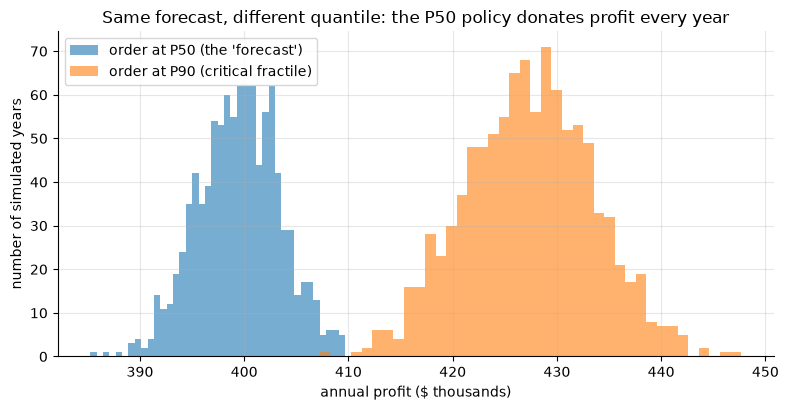

In [6]:
# Verify by simulating 1,000 years of daily demand under both policies.
n_years = 1_000
d = np.maximum(rng.normal(mu_day, sigma_day, size=(n_years, n_days)), 0.0)

def realized_profit(order_qty, demand, price, cost, salvage):
    sold = np.minimum(demand, order_qty)
    return price * sold + salvage * (order_qty - sold) - cost * order_qty

annual_sim_p50 = realized_profit(forecast["P50"].values, d, price_b, cost_b, salvage_b).sum(axis=1)
annual_sim_p90 = realized_profit(forecast["P90"].values, d, price_b, cost_b, salvage_b).sum(axis=1)

print(f"simulated mean annual gap (P90 - P50): ${np.mean(annual_sim_p90 - annual_sim_p50):,.0f}"
      f"  (formula said ${annual_p90 - annual_p50:,.0f})")
print(f"P90 policy beats P50 policy in {np.mean(annual_sim_p90 > annual_sim_p50):.1%} of years")
leftover_days = np.mean(d < forecast["P90"].values)
print(f"...even though the P90 policy has leftovers on {leftover_days:.0%} of days")

fig, ax = plt.subplots()
ax.hist(annual_sim_p50 / 1e3, bins=40, alpha=0.6, label="order at P50 (the 'forecast')")
ax.hist(annual_sim_p90 / 1e3, bins=40, alpha=0.6, label="order at P90 (critical fractile)")
ax.set_xlabel("annual profit ($ thousands)")
ax.set_ylabel("number of simulated years")
ax.set_title("Same forecast, different quantile: the P50 policy donates profit every year")
ax.legend()
plt.show()

The senior talking points:

- **A forecast is not a decision.** The forecast's job is a calibrated distribution; the
  decision layer picks the quantile that the *cost structure* dictates. Decoupling these two
  is the whole design: forecasting teams optimize pinball loss, planners own $c_u, c_o$.
- The optimal policy **looks wasteful**: ~90% of days end with unsold berries. Expect to
  defend this to a stakeholder — "if we never throw anything away, we are under-ordering" is
  the one-line version.
- If CF lands between provided quantiles (say CF = 0.83 with only P10/P50/P90), interpolate
  or fit a distribution through the quantiles — and if CF > 0.9, go back to the forecast team
  for deeper tail quantiles rather than extrapolating blindly.

## 3. Multi-period inventory: (s, S) policies, lead time, and the service/cost frontier

Real inventory isn't single-period: stock carries over, replenishment takes a **lead time**
$L$, and you pay to hold. A standard periodic-review policy is **(s, S)**: each day, after
demand, if **inventory position** (on hand + on order) $\le s$, order up to $S$; the order
arrives $L$ days later. Costs:

- holding $h$ per unit per day (capital, storage, shrink),
- lost margin per unit of unmet demand (we model **lost sales**, the retail case;
  backorders are the B2B variant),
- fixed cost $K$ per order placed (receiving, freight minimums).

There is no clean closed form for lost-sales (s, S) with lead time — this is exactly where
**Monte Carlo over the inventory process** becomes the tool. We simulate the daily state
recursion over many replications, sweep $s$, and trace the **service-level vs holding-cost
frontier**. Note the two service metrics we record — they will disagree, on purpose
(see Pitfalls):

- **fill rate** (type 2): fraction of demanded units served,
- **daily no-stockout rate** (a type-1-style cycle proxy): fraction of days with no shortfall.

In [7]:
def simulate_sS(s, S, demand, lead_time=5, warmup=50):
    """Periodic-review (s,S), lost sales, fixed lead time. demand: (reps, days)."""
    reps, days = demand.shape
    on_hand = np.full(reps, float(S))
    on_order = np.zeros(reps)
    arrivals = np.zeros((reps, days + lead_time + 1))   # pipeline of in-transit orders
    on_hand_hist = np.zeros((reps, days))
    short_hist = np.zeros((reps, days))
    order_hist = np.zeros((reps, days))

    for t in range(days):
        on_hand += arrivals[:, t]                       # receive
        on_order -= arrivals[:, t]
        d = demand[:, t]
        sold = np.minimum(d, on_hand)                   # serve (excess demand is lost)
        short_hist[:, t] = d - sold
        on_hand -= sold
        on_hand_hist[:, t] = on_hand
        position = on_hand + on_order                   # review + order
        trigger = position <= s
        qty = np.where(trigger, S - position, 0.0)
        arrivals[:, t + lead_time] += qty
        on_order += qty
        order_hist[:, t] = trigger

    sl = np.s_[:, warmup:]
    n_days = days - warmup
    return {
        "s": s, "S": S,
        "fill_rate": 1.0 - short_hist[sl].sum() / demand[sl].sum(),
        "no_stockout_days": 1.0 - (short_hist[sl] > 0).mean(),
        "avg_on_hand": on_hand_hist[sl].mean(),
        "orders_per_year": order_hist[sl].sum() / reps / n_days * 365,
        "lost_units_per_year": short_hist[sl].sum() / reps / n_days * 365,
    }


# Daily demand: gamma, mean 100, CV 0.4 (right-skewed, realistic for a mid-velocity SKU)
mean_d, cv_d = 100.0, 0.4
shape_g = 1 / cv_d**2
reps, horizon = 300, 415                 # 50-day warmup + ~1 year measured
demand_mat = rng.gamma(shape_g, mean_d / shape_g, size=(reps, horizon))

LEAD, HOLD, MARGIN, K_ORDER = 5, 0.05, 4.0, 100.0   # h $/unit/day, lost margin $/unit, $/order
mu_LTD = LEAD * mean_d                              # mean lead-time demand = 500

# Common random numbers: every policy sees the SAME demand paths, so differences
# between rows are pure policy effect, not simulation noise.
sweep = pd.DataFrame([simulate_sS(s, s + 400, demand_mat, LEAD) for s in range(450, 901, 50)])
sweep["safety_stock"] = sweep["s"] - mu_LTD
sweep["holding_per_year"] = sweep["avg_on_hand"] * HOLD * 365
sweep["fixed_per_year"] = sweep["orders_per_year"] * K_ORDER
sweep["lost_margin_per_year"] = sweep["lost_units_per_year"] * MARGIN
sweep["total_cost"] = sweep[["holding_per_year", "fixed_per_year", "lost_margin_per_year"]].sum(axis=1)
sweep.round(3)

,s,S,fill_rate,no_stockout_days,avg_on_hand,orders_per_year,lost_units_per_year,safety_stock,holding_per_year,fixed_per_year,lost_margin_per_year,total_cost
0,450,850,0.925,0.877,206.490,74.233,2749.772,-50.0,3768.444,7423.333,10999.088,22190.865
1,500,900,0.964,0.933,245.079,77.617,1319.603,0.0,4472.691,7761.667,5278.410,17512.768
2,550,950,0.984,0.967,286.734,78.757,598.365,50.0,5232.896,7875.667,2393.459,15502.022
3,600,1000,0.993,0.985,331.699,79.203,242.383,100.0,6053.501,7920.333,969.532,14943.367
4,650,1050,0.998,0.995,379.249,79.423,86.419,150.0,6921.287,7942.333,345.677,15209.297
5,700,1100,0.999,0.998,428.248,79.513,26.270,200.0,7815.533,7951.333,105.081,15871.948
6,750,1150,1.000,0.999,477.919,79.543,7.329,250.0,8722.026,7954.333,29.317,16705.676
7,800,1200,1.000,1.000,527.834,79.543,2.274,300.0,9632.970,7954.333,9.094,17596.397
8,850,1250,1.000,1.000,577.821,79.550,0.756,350.0,10545.234,7955.000,3.023,18503.258
9,900,1300,1.000,1.000,627.819,79.550,0.186,400.0,11457.704,7955.000,0.745,19413.449


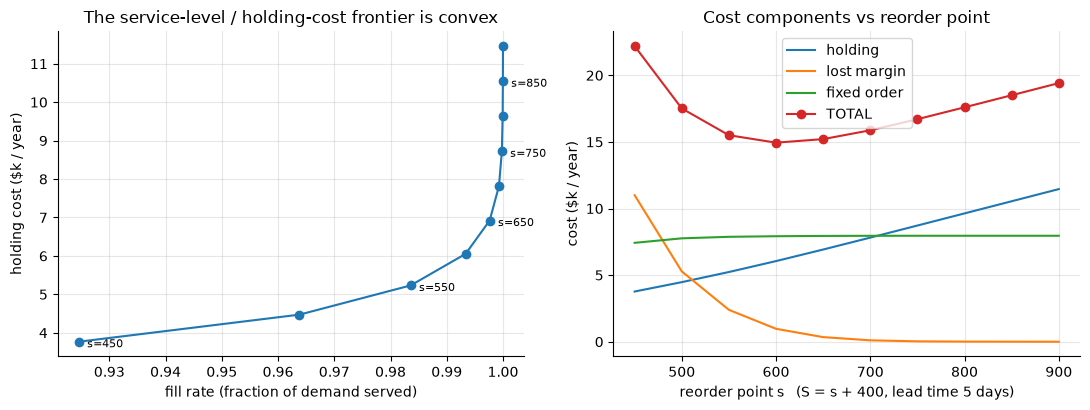

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ax = axes[0]
ax.plot(sweep["fill_rate"], sweep["holding_per_year"] / 1e3, "o-")
for _, r in sweep.iloc[::2].iterrows():
    ax.annotate(f"s={r['s']:.0f}", (r["fill_rate"], r["holding_per_year"] / 1e3),
                textcoords="offset points", xytext=(6, -4), fontsize=8)
ax.set_xlabel("fill rate (fraction of demand served)")
ax.set_ylabel("holding cost ($k / year)")
ax.set_title("The service-level / holding-cost frontier is convex")

ax = axes[1]
for col, lab in [("holding_per_year", "holding"), ("lost_margin_per_year", "lost margin"),
                 ("fixed_per_year", "fixed order"), ("total_cost", "TOTAL")]:
    ax.plot(sweep["s"], sweep[col] / 1e3, "o-" if col == "total_cost" else "-", label=lab)
ax.set_xlabel("reorder point s   (S = s + 400, lead time 5 days)")
ax.set_ylabel("cost ($k / year)")
ax.set_title("Cost components vs reorder point")
ax.legend()
plt.show()

In [9]:
# Choosing a policy for a target service level, and pricing the next "nine"
target = 0.98
chosen = sweep[sweep["fill_rate"] >= target].iloc[0]   # smallest s that clears the target
hi = sweep[sweep["fill_rate"] >= 0.995].iloc[0]        # "we want another nine"
best = sweep.loc[sweep["total_cost"].idxmin()]

print(f"target fill rate {target:.0%} -> choose s = {chosen['s']:.0f} "
      f"(achieved {chosen['fill_rate']:.2%}, safety stock {chosen['safety_stock']:.0f} u, "
      f"holding ${chosen['holding_per_year']:,.0f}/yr)")
print(f"pushing to 99.5%        -> s = {hi['s']:.0f} "
      f"(achieved {hi['fill_rate']:.2%}, safety stock {hi['safety_stock']:.0f} u, "
      f"holding ${hi['holding_per_year']:,.0f}/yr)")
print(f"  the next 'nine' costs {hi['safety_stock'] / chosen['safety_stock']:.1f}x the "
      f"safety stock and +${hi['holding_per_year'] - chosen['holding_per_year']:,.0f}/yr "
      f"holding ({hi['holding_per_year'] / chosen['holding_per_year'] - 1:+.0%})")
print(f"unconstrained cost-minimizing policy: s = {best['s']:.0f} "
      f"(fill {best['fill_rate']:.2%}, total ${best['total_cost']:,.0f}/yr) — "
      f"with these economics the optimum already sits at a high fill rate")

target fill rate 98% -> choose s = 550 (achieved 98.36%, safety stock 50 u, holding $5,233/yr)
pushing to 99.5%        -> s = 650 (achieved 99.76%, safety stock 150 u, holding $6,921/yr)
  the next 'nine' costs 3.0x the safety stock and +$1,688/yr holding (+32%)
unconstrained cost-minimizing policy: s = 600 (fill 99.34%, total $14,943/yr) — with these economics the optimum already sits at a high fill rate


Reading the frontier like a senior candidate:

- The frontier is **convex**: each additional point of service costs more than the last,
  because you are buying quantiles ever deeper into the demand tail. This chart *is* the
  negotiation tool for "the warehouse wants 99%".
- Sometimes the cost-minimizing policy already implies a high fill rate (high margin, cheap
  holding). Then the fight isn't service vs cost — state it and move on. The tension appears
  when holding is expensive or margin thin.
- Simulation methodology: **common random numbers** across the policy sweep (one demand
  matrix, all policies) makes the frontier smooth; independent draws per policy would need
  many more replications for the same comparison precision. And always **discard a warmup**
  — we start full at $S$, which flatters the early days.

## 4. Safety stock: the formula, and where it breaks

The textbook continuous-review rule: reorder when inventory position hits

$$ \text{ROP} = \underbrace{\mu_d L}_{\text{expected lead-time demand}}
   + \underbrace{z_\alpha\, \sigma_d \sqrt{L}}_{\text{safety stock}}, $$

which targets a cycle service level $\alpha$: $P(D_L \le \text{ROP}) = \alpha$. It assumes
lead-time demand $D_L$ is **normal** — true if daily demand is iid normal (or $L$ is large
enough for the CLT to rescue you), and crucially that daily demands are **independent**, so
that $\text{Var}(D_L) = L\sigma_d^2$.

Both assumptions fail routinely: demand is right-skewed (promo spikes, B2B lumps) and
**autocorrelated** (trends, weather, viral effects — high days cluster). We test the formula
against simulated lead-time demand under three demand processes with **identical daily mean
and standard deviation** (100 ± 40, $L = 4$):

1. iid normal — the formula's home turf,
2. iid lognormal (skew ≈ 1.3) — same first two moments, heavier right tail,
3. AR(1) with $\phi = 0.7$ — same *marginal* moments, but high days cluster inside the
   lead-time window.

In [10]:
L4, mu4, sd4 = 4, 100.0, 40.0
n_win = 200_000

# (1) iid normal lead-time demand
ltd_normal = rng.normal(mu4, sd4, size=(n_win, L4)).sum(axis=1)

# (2) iid lognormal, moment-matched to mean 100, sd 40
s2 = math.log(1 + (sd4 / mu4) ** 2)
ltd_lognorm = rng.lognormal(math.log(mu4) - s2 / 2, math.sqrt(s2),
                            size=(n_win, L4)).sum(axis=1)

# (3) AR(1), phi=0.7, marginal moments matched; overlapping windows from one long path
phi = 0.7
eps = rng.normal(0, sd4 * math.sqrt(1 - phi**2), size=400_000)
path = np.empty_like(eps)
path[0] = mu4
for t in range(1, len(eps)):                      # x_t = mu + phi(x_{t-1}-mu) + eps_t
    path[t] = mu4 + phi * (path[t - 1] - mu4) + eps[t]
csum = np.cumsum(path)
ltd_ar1 = csum[L4:] - csum[:-L4]

cases = {"iid normal": ltd_normal, "iid lognormal (skewed)": ltd_lognorm,
         "AR(1) phi=0.7 (autocorrelated)": ltd_ar1}
for name, x in cases.items():
    print(f"{name:32s} lead-time demand: mean {x.mean():6.1f}, sd {x.std():6.1f}")
print(f"{'formula assumes':32s} lead-time demand: mean {L4 * mu4:6.1f}, "
      f"sd {sd4 * math.sqrt(L4):6.1f}   <- AR(1) sd is much larger")

iid normal                       lead-time demand: mean  400.4, sd   79.8
iid lognormal (skewed)           lead-time demand: mean  400.2, sd   80.1
AR(1) phi=0.7 (autocorrelated)   lead-time demand: mean  400.3, sd  131.3
formula assumes                  lead-time demand: mean  400.0, sd   80.0   <- AR(1) sd is much larger


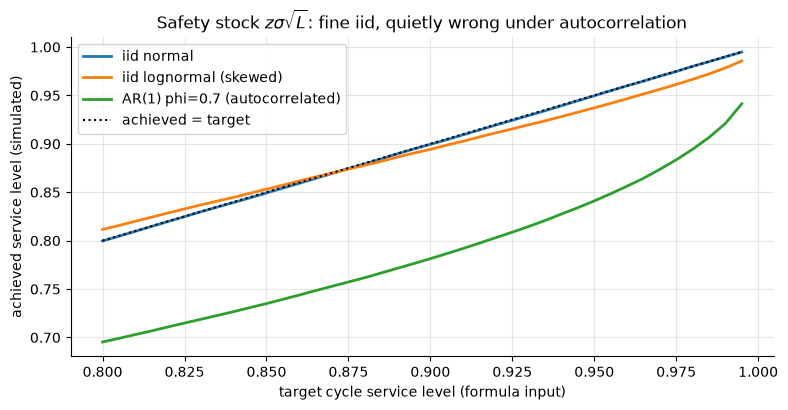

,iid normal,iid lognormal (skewed),AR(1) phi=0.7 (autocorrelated)
target,,,
0.95,0.95,0.937,0.841
0.99,0.99,0.978,0.921


In [11]:
targets = np.linspace(0.80, 0.995, 40)
rop_formula = L4 * mu4 + stats.norm.ppf(targets) * sd4 * math.sqrt(L4)

fig, ax = plt.subplots()
achieved = {}
for name, x in cases.items():
    xs = np.sort(x)
    achieved[name] = np.searchsorted(xs, rop_formula) / len(xs)   # P(D_L <= ROP)
    ax.plot(targets, achieved[name], lw=2, label=name)
ax.plot(targets, targets, "k:", label="achieved = target")
ax.set_xlabel("target cycle service level (formula input)")
ax.set_ylabel("achieved service level (simulated)")
ax.set_title(r"Safety stock $z\sigma\sqrt{L}$: fine iid, quietly wrong under autocorrelation")
ax.legend()
plt.show()

rows = []
for tgt in (0.95, 0.99):
    i = np.argmin(np.abs(targets - tgt))
    rows.append({"target": tgt, **{k: v[i] for k, v in achieved.items()}})
pd.DataFrame(rows).set_index("target").round(3)

- **Skewed demand**: mild damage. Summing 4 days pulls $D_L$ toward normal (CLT), but the
  heavy right tail still bites at high targets — a 99% input delivers ~98%. With shorter
  lead times or lumpier demand the gap widens.
- **Autocorrelated demand**: severe damage — a **95% target delivers ~84%**. The formula's
  $\sqrt{L}$ scaling assumes independence; with $\phi = 0.7$,
  $\text{Var}(D_L) = \sigma^2\big(L + 2\sum_{k=1}^{L-1}(L-k)\phi^k\big) \approx 2.7 \times L\sigma^2$.
  High-demand days arrive in runs, exactly when your pipeline is thinnest. This is the most
  common silent failure in real deployments: the *marginal* histogram of demand looks fine,
  so nobody suspects the formula.

**The fix is embarrassingly simple**: don't model daily demand and scale — take **historical
$L$-day sums** (which embed any dependence structure automatically) and use their empirical
quantile as the ROP. That's simulation-based safety stock with the data as the simulator.

In [12]:
# Fix demonstrated: empirical quantile of L-day sums from 3 years of "history"
history = path[:1095]
hist_sums = np.convolve(history, np.ones(L4), mode="valid")
rop_hist = np.quantile(hist_sums, 0.95)

# correct analytic variance for AR(1), for comparison
var_corr = sd4**2 * (L4 + 2 * sum((L4 - k) * phi**k for k in range(1, L4)))
rop_analytic_corr = L4 * mu4 + stats.norm.ppf(0.95) * math.sqrt(var_corr)

eval_sums = ltd_ar1[len(history):]                     # held-out evaluation windows
for name, rop in [("naive formula (z*sigma*sqrt(L))", rop_formula[np.argmin(np.abs(targets - 0.95))]),
                  ("empirical 95% of historical L-day sums", rop_hist),
                  ("formula with CORRECT AR(1) variance", rop_analytic_corr)]:
    print(f"{name:42s} ROP = {rop:6.0f} -> achieved {np.mean(eval_sums <= rop):.1%} "
          f"(target 95%)")

naive formula (z*sigma*sqrt(L))            ROP =    532 -> achieved 84.1% (target 95%)
empirical 95% of historical L-day sums     ROP =    616 -> achieved 95.0% (target 95%)
formula with CORRECT AR(1) variance        ROP =    617 -> achieved 95.0% (target 95%)


## 5. Discrete-event simulation: the senior swiss-army knife

Sections 3–4 vectorized over a fixed daily clock. Queues, service desks, fulfillment lines —
anything where *events* (arrivals, completions) happen at irregular times — want a
**discrete-event simulation (DES)**: a priority queue of timestamped callbacks. Time jumps
from event to event; each event mutates state and schedules future events.

The entire engine is ~15 lines of plain Python — no SimPy required. Knowing that the engine
is *this* small is the senior move: when an interviewer changes the physics ("what if
customers hang up after 2 minutes?"), you edit one callback instead of hunting for a formula
that no longer exists.

In [13]:
class EventLoop:
    """Minimal discrete-event simulator: a heap of (time, seq, callback)."""

    def __init__(self):
        self.now = 0.0
        self._pq = []
        self._seq = itertools.count()        # tie-breaker: FIFO among simultaneous events

    def schedule(self, delay, callback):
        heapq.heappush(self._pq, (self.now + delay, next(self._seq), callback))

    def run(self):
        while self._pq:
            self.now, _, cb = heapq.heappop(self._pq)
            cb()


def simulate_mmc(lam, c, n_customers, rng, mean_service=1.0, warmup_frac=0.2):
    """M/M/c FCFS queue on the event loop. Returns per-customer waits (post-warmup)."""
    inter = rng.exponential(1 / lam, n_customers).tolist()
    serv = rng.exponential(mean_service, n_customers).tolist()
    loop, queue, waits = EventLoop(), deque(), []
    free = c
    nxt = {"i": 0}

    def start_service(arrival_time, svc):
        waits.append(loop.now - arrival_time)
        loop.schedule(svc, depart)

    def depart():
        nonlocal free
        if queue:
            start_service(*queue.popleft())   # server grabs the next customer
        else:
            free += 1

    def arrive():
        nonlocal free
        i = nxt["i"]
        nxt["i"] += 1
        if i + 1 < n_customers:
            loop.schedule(inter[i + 1], arrive)
        if free:
            free -= 1
            start_service(loop.now, serv[i])
        else:
            queue.append((loop.now, serv[i]))

    loop.schedule(inter[0], arrive)
    loop.run()
    return np.asarray(waits[int(n_customers * warmup_frac):])


# Sanity check against the one queue everyone can solve by hand: M/M/1 at rho = 0.8
w = simulate_mmc(lam=0.8, c=1, n_customers=60_000, rng=rng)
print(f"M/M/1, rho=0.8:  simulated Wq = {w.mean():.2f}   "
      f"analytic rho/(1-rho) = {0.8 / 0.2:.2f}  (service-time units)")

M/M/1, rho=0.8:  simulated Wq = 3.79   analytic rho/(1-rho) = 4.00  (service-time units)


## 6. Queueing for operations: staffing a support team (M/M/c vs Erlang C)

**Scenario**: chat support. Contacts arrive Poisson at rate $\lambda$, handle times are
exponential with mean $1/\mu$, $c$ agents serve FCFS. Two numbers rule everything:

- **offered load** $a = \lambda / \mu$ (erlangs) — the average number of busy agents,
- **utilization** $\rho = a / c$.

The analytic benchmark is **Erlang C**: the probability an arrival waits is

$$ C(c, a) = \frac{\frac{a^c}{c!}\frac{1}{1-\rho}}
             {\sum_{k=0}^{c-1}\frac{a^k}{k!} + \frac{a^c}{c!}\frac{1}{1-\rho}},
\qquad W_q = \frac{C(c, a)}{c\mu - \lambda}, \qquad
P(W > t) = C(c,a)\,e^{-(c\mu - \lambda)t}. $$

Note the $1/(c\mu - \lambda) = \frac{1}{c\mu}\cdot\frac{1}{1-\rho}$ factor: wait time has a
**pole at $\rho = 1$**. That's the whole story of the "80% cliff".

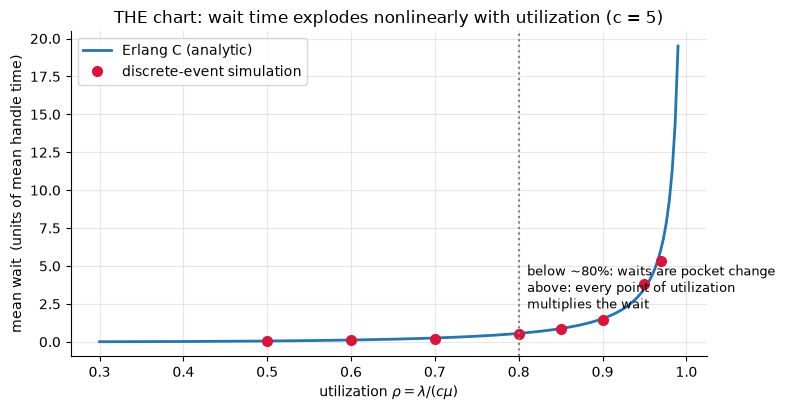

rho:       0.50   0.60   0.70   0.80   0.85   0.90   0.95   0.97
Wq sim:    0.05   0.11   0.21   0.51   0.82   1.43   3.84   5.31
Wq Erlang: 0.05   0.12   0.25   0.55   0.87   1.52   3.51   6.17


In [14]:
def erlang_c(c, a):
    """P(arrival waits) for M/M/c with offered load a = lambda/mu."""
    if a >= c:
        return 1.0
    rho = a / c
    below = sum(a**k / math.factorial(k) for k in range(c))
    top = a**c / math.factorial(c) / (1 - rho)
    return top / (below + top)


def wq_mmc(c, a, mean_service=1.0):
    """Mean wait in queue (same time units as mean_service)."""
    return np.inf if a >= c else erlang_c(c, a) * mean_service / (c - a)


# THE chart: c = 5 agents, sweep utilization. Simulation dots must land on the Erlang-C curve.
c_team = 5
rho_curve = np.linspace(0.30, 0.99, 200)
wq_curve = [wq_mmc(c_team, r * c_team) for r in rho_curve]

rho_sim = np.array([0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95, 0.97])
# near saturation waiting-time variance blows up, so those points need far longer runs
wq_sim = [simulate_mmc(r * c_team, c_team, 30_000 if r < 0.9 else 150_000, rng).mean()
          for r in rho_sim]

fig, ax = plt.subplots()
ax.plot(rho_curve, wq_curve, lw=2, label="Erlang C (analytic)")
ax.plot(rho_sim, wq_sim, "o", ms=7, color="crimson", label="discrete-event simulation")
ax.axvline(0.80, color="gray", ls=":")
ax.annotate("below ~80%: waits are pocket change\nabove: every point of utilization\n"
            "multiplies the wait", xy=(0.81, 2.2), fontsize=9)
ax.set_xlabel(r"utilization $\rho = \lambda / (c\mu)$")
ax.set_ylabel("mean wait  (units of mean handle time)")
ax.set_title("THE chart: wait time explodes nonlinearly with utilization (c = 5)")
ax.legend()
plt.show()

print("rho:      " + "  ".join(f"{r:5.2f}" for r in rho_sim))
print("Wq sim:   " + "  ".join(f"{x:5.2f}" for x in wq_sim))
print("Wq Erlang:" + "  ".join(f"{wq_mmc(c_team, r * c_team):5.2f}" for r in rho_sim))

Why the explosion (the answer interviewers want, in three layers):

1. **Algebra**: $W_q \propto \frac{1}{1-\rho}$. Going 0.80 → 0.90 → 0.95 → 0.975 doubles the
   wait each step. Nothing about queues is linear near saturation.
2. **Mechanism**: the queue drains at rate $c\mu - \lambda$ — the *slack*. At high $\rho$
   slack is tiny, so a random burst of arrivals takes ages to clear, and the next burst lands
   before recovery. Waits are caused by *variability meeting insufficient slack*, which is
   why deterministic "average load" thinking fails (see Pitfalls).
3. **Generality**: Kingman's approximation
   $W_q \approx \frac{\rho}{1-\rho}\cdot\frac{CV_a^2 + CV_s^2}{2}\cdot \frac{1}{\mu}$ —
   the $\frac{1}{1-\rho}$ pole survives for general arrival/service distributions;
   variability enters multiplicatively. Cutting variability (fewer batch uploads, better
   routing) buys the same relief as adding capacity.

Also notice the simulation dots get visibly noisier near $\rho \to 1$ even with 30k
customers per point — waiting-time variance blows up too. Near saturation the analytic form
isn't just elegant, it's *more accurate per CPU-second* than simulation.

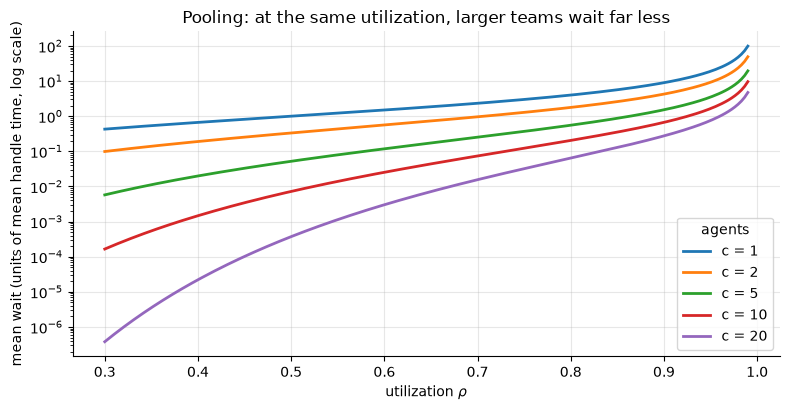

at rho = 0.90: Wq(c=1) = 9.00 service times, Wq(c=20) = 0.28 — same utilization, ~33x less waiting.
Corollaries: merge queues/skills where possible; small teams need MORE slack, not less.


In [15]:
# The pooling effect: bigger teams can safely run hotter
fig, ax = plt.subplots()
for c in (1, 2, 5, 10, 20):
    ax.semilogy(rho_curve, [wq_mmc(c, r * c) for r in rho_curve], lw=2, label=f"c = {c}")
ax.set_xlabel(r"utilization $\rho$")
ax.set_ylabel("mean wait (units of mean handle time, log scale)")
ax.set_title("Pooling: at the same utilization, larger teams wait far less")
ax.legend(title="agents")
plt.show()
print(f"at rho = 0.90: Wq(c=1) = {wq_mmc(1, 0.9):.2f} service times, "
      f"Wq(c=20) = {wq_mmc(20, 18):.2f} — same utilization, ~{wq_mmc(1, 0.9) / wq_mmc(20, 18):.0f}x less waiting.")
print("Corollaries: merge queues/skills where possible; small teams need MORE slack, not less.")

In [16]:
# Staffing decision: lambda = 50 contacts/hr, mean handle time 6 min -> a = 5 erlangs.
# SLA: 80% of chats answered within 30 seconds. How many agents?
lam_min, aht = 50 / 60.0, 6.0          # per-minute arrival rate, minutes of handle time
a_load = lam_min * aht
rows = []
for c in range(6, 11):
    pw = erlang_c(c, a_load)
    drain = c / aht - lam_min                          # c*mu - lambda, per minute
    sim_w = simulate_mmc(lam_min, c, 30_000, rng, mean_service=aht)
    rows.append({
        "agents": c,
        "utilization": a_load / c,
        "P(wait) erlang": pw,
        "P(wait) sim": np.mean(sim_w > 1e-12),
        "Wq erlang (min)": pw / drain,
        "Wq sim (min)": sim_w.mean(),
        "SL 30s erlang": 1 - pw * math.exp(-drain * 0.5),
        "SL 30s sim": np.mean(sim_w <= 0.5),
    })
staffing = pd.DataFrame(rows).set_index("agents")
print(f"offered load a = {a_load:.1f} erlangs (5 agents' worth of pure work)")
staffing.round(3)

offered load a = 5.0 erlangs (5 agents' worth of pure work)


,utilization,P(wait) erlang,P(wait) sim,Wq erlang (min),Wq sim (min),SL 30s erlang,SL 30s sim
agents,,,,,,,
6,0.833,0.588,0.578,3.525,3.085,0.459,0.467
7,0.714,0.324,0.334,0.972,1.112,0.726,0.718
8,0.625,0.167,0.162,0.335,0.293,0.870,0.874
9,0.556,0.081,0.083,0.121,0.128,0.942,0.940
10,0.500,0.036,0.040,0.043,0.052,0.976,0.972


Simulation and Erlang C agree within Monte Carlo noise — the DES is validated, which is
precisely what licenses it for the questions Erlang C *can't* answer (abandonment, callbacks,
priority tiers, lunch breaks — see Exercise 3).

The staffing answer: **7 agents miss** the 80%-in-30s SLA, **8 agents clear it** with room
to spare, at ~63% utilization. The jump from "5 agents of load" to "8 agents needed" is the
queueing tax on variability — capacity planning by average load (5 agents, $\rho=1$) is not
conservative, it is *divergent*.

## 7. Pitfalls

Each demonstrated, not just described.

### Pitfall 1: The flaw of averages — planning capacity for mean load

In [17]:
# "Load is 5 erlangs, so 5 agents suffice" -> rho = 1.0 -> the queue never stabilizes.
# Symptom in simulation: mean wait keeps GROWING with run length (there is no steady state).
for n in (500, 2_000, 8_000):
    means = [simulate_mmc(lam_min, 5, n, rng, mean_service=aht, warmup_frac=0.0).mean()
             for _ in range(25)]
    print(f"c=5 (rho=1.00): first {n:>5,} customers -> mean wait {np.mean(means):6.1f} min "
          "(avg of 25 runs — still climbing)")
print(f"c=6 (rho=0.83): steady state exists, Wq = {wq_mmc(6, 5, aht):.1f} min")
print("Deterministic thinking says c=5 'meets demand'. With variability, the queue diverges;")
print("Jensen's inequality in ops clothing: E[wait(load)] >> wait(E[load]).")

c=5 (rho=1.00): first   500 customers -> mean wait   16.4 min (avg of 25 runs — still climbing)
c=5 (rho=1.00): first 2,000 customers -> mean wait   35.7 min (avg of 25 runs — still climbing)


c=5 (rho=1.00): first 8,000 customers -> mean wait   68.4 min (avg of 25 runs — still climbing)
c=6 (rho=0.83): steady state exists, Wq = 3.5 min
Deterministic thinking says c=5 'meets demand'. With variability, the queue diverges;
Jensen's inequality in ops clothing: E[wait(load)] >> wait(E[load]).


### Pitfall 2: "95% service level" — which service level?

Fill rate (units served / units demanded) and no-stockout frequency are **different numbers
for the same policy**, and vendors/warehouses quote whichever flatters them. From the
Section-3 sweep:

In [18]:
cmp_metrics = sweep[["s", "fill_rate", "no_stockout_days"]].copy()
cmp_metrics["gap (pts)"] = 100 * (cmp_metrics["no_stockout_days"] - cmp_metrics["fill_rate"])
print(cmp_metrics.round(4).to_string(index=False))
print("\nSame policy, same simulation — metrics differ by several points, and the DIRECTION")
print("depends on whether stockouts are frequent-but-small or rare-but-deep. Always pin down")
print("the metric (fill rate vs cycle service vs OTIF) before agreeing to a number.")

  s  fill_rate  no_stockout_days  gap (pts)
450     0.9246            0.8766    -4.7930
500     0.9638            0.9334    -3.0385
550     0.9836            0.9673    -1.6280
600     0.9934            0.9854    -0.7935
650     0.9976            0.9945    -0.3081
700     0.9993            0.9980    -0.1243
750     0.9998            0.9995    -0.0319
800     0.9999            0.9998    -0.0093
850     1.0000            1.0000    -0.0025
900     1.0000            1.0000    -0.0013

Same policy, same simulation — metrics differ by several points, and the DIRECTION
depends on whether stockouts are frequent-but-small or rare-but-deep. Always pin down
the metric (fill rate vs cycle service vs OTIF) before agreeing to a number.


### Pitfall 3: Trusting a short, un-warmed-up simulation

A queue started empty spends its early history below steady state. Estimating $W_q$ from a
short run (or keeping the warmup in your average) biases waits low — you'll happily staff
too thin and discover the truth in production.

In [19]:
short_means = [simulate_mmc(0.9 * c_team, c_team, 300, rng, warmup_frac=0.0).mean()
               for _ in range(200)]
long_run = simulate_mmc(0.9 * c_team, c_team, 60_000, rng).mean()
truth = wq_mmc(c_team, 0.9 * c_team)
print(f"rho=0.90, c=5.  True Wq (Erlang C):            {truth:.2f}")
print(f"long run, warmup discarded:                    {long_run:.2f}")
print(f"mean of 200 SHORT runs (300 cust., no warmup): {np.mean(short_means):.2f} "
      f"-> {(np.mean(short_means) / truth - 1):+.0%} bias")
print("The fix: warm up + long runs + replications; or better, cross-check any simulated")
print("steady-state number against an analytic special case before believing it.")

rho=0.90, c=5.  True Wq (Erlang C):            1.52
long run, warmup discarded:                    1.58
mean of 200 SHORT runs (300 cust., no warmup): 0.93 -> -39% bias
The fix: warm up + long runs + replications; or better, cross-check any simulated
steady-state number against an analytic special case before believing it.


## 8. Interview corner

**Q1. "We're launching a seasonal item. How much should we order?"**
Strong answer: recognize the newsvendor. (1) Get the economics: margin per lost sale
($c_u$), net loss per leftover after markdown/salvage ($c_o$). (2) Critical fractile
$c_u/(c_u+c_o)$. (3) Order that quantile of the demand forecast — from comps for a new item,
and as a *distribution*, not a point. Mention: one-shot vs reorder opportunity (reorders
lower the stakes → order less initially), budget/space constraints across SKUs (rank by
marginal expected profit), and demand **censoring** in historicals — sales data truncated by
past stockouts understates demand; correct before fitting.

**Q2. "Why does wait time explode when utilization gets high?"**
Strong answer: $W_q \propto 1/(1-\rho)$ — a pole, not a slope. Mechanism: slack $c\mu -
\lambda$ is the queue's drain rate; near saturation, bursts arrive faster than the slack
clears them, so delays compound. Cite Kingman: variability (arrival + service CV) multiplies
the effect, so it's variability × utilization, not utilization alone. Bonus points: pooling
(bigger $c$ tolerates higher $\rho$), and the practical rule that ~80–85% utilization is the
knee for small-to-mid teams.

**Q3. "The warehouse wants a 99% service level. Walk me through it."**
Strong answer: first, *which* metric — fill rate, cycle service, OTIF? They differ by
points (Pitfall 2). Then show the convex frontier: safety stock scales with $z_\alpha$, so
each extra point of service costs more than the last (and heavy tails make the true cost
worse than normal math suggests — Section 4). Quantify from your own sim: in our sweep,
pushing fill from 98% to 99.5% **tripled** the safety stock.
Then negotiate like an economist: is a lost sale really worth it? Segment — 99% on A
items, 90% on C items beats 97% on everything for the same capital. And often the cheapest
route to service isn't stock at all: shorten lead time or cut forecast error, since safety
stock $\propto \sigma \sqrt{L}$.

**Q4. "When do you simulate vs solve analytically?"**
Strong answer: analytic when assumptions hold and you need speed, gradients, or insight —
closed forms live inside optimization loops and explain *why* (the $1/(1-\rho)$ pole, the
critical fractile). Simulate when reality breaks the assumptions: state-dependent policies,
lost sales with lead times, order crossing, abandonment, autocorrelated or empirical
demand, tail percentile SLAs. Best practice is **both**: validate the simulator on an
analytic special case (our DES vs Erlang C), then extend it beyond where formulas reach.
Know simulation's costs: warmup bias, variance near saturation, and use CRN when comparing
policies.

**Q5. "The forecasting team gives you P10/P50/P90. How do you set the order?"**
Strong answer: compute the critical fractile from unit economics; order that quantile.
CF between the given quantiles → interpolate or fit a parametric distribution through them;
CF beyond P90 → ask the forecast team for deeper quantiles rather than extrapolating a
straight line into the tail. Explicitly reject "order the P50": the median is optimal only
when overage and underage costs are equal, and the expected cost of that mistake is
computable (Section 2 — ~7% of annual profit in our example).

**Q6. "Design reorder points for 10,000 SKUs."**
Strong answer: segment first (ABC by revenue × demand pattern: smooth / intermittent /
lumpy). Fast smooth movers: formula-based with service targets by segment economics. Lumpy,
autocorrelated, or short-history SKUs: empirical lead-time-demand quantiles (historical
L-day sums) or simulation. Then close the loop: backtest policies against held-out history
with a simulator, monitor achieved fill vs target per segment, and re-tune. Mention censored
demand and lead-time variability as the two data traps.

## 9. Key takeaways

- The optimal order is a **quantile**, set by the cost ratio $c_u/(c_u+c_o)$ — not the
  forecast mean. Brute-force simulation over $Q$ reproduces the closed form exactly.
- Forecasting and deciding are separable: calibrated quantiles from the forecast system,
  critical fractile from unit economics. Ordering at P50 when CF = 0.9 burned ~7% of annual
  profit in our example — with the *same* forecast.
- Optimal policies look wasteful on purpose: high-CF products should have leftovers most
  days; low waits require idle agents. Budget the political capital to defend slack.
- Multi-period inventory with lead times and lost sales has no tidy closed form — Monte
  Carlo the state recursion, sweep the policy, and read the **convex** service/cost frontier.
- Safety stock $z\sigma\sqrt{L}$ silently understocks under autocorrelation (95% target →
  ~84% achieved at $\phi=0.7$); empirical quantiles of historical $L$-day sums fix it for free.
- $W_q \propto 1/(1-\rho)$: capacity planning is nonlinear; ~80% utilization is the knee.
  Variability multiplies the pain (Kingman); pooling relieves it.
- Staff to the SLA via Erlang C or DES — never to average load; $\rho = 1$ diverges.
- A discrete-event simulator is a heap of timestamped callbacks — ~15 lines. Validate it
  against an analytic case, then extend to the physics formulas can't reach.
- Simulation hygiene: seed it, warm it up, replicate it, use common random numbers for
  policy comparisons, and distrust it near saturation.

## 10. Exercises

**Exercise 1 — distribution-free newsvendor.** You have only 120 days of historical demand
for the bakery (no distributional assumption). (a) Compute the order quantity from the
empirical critical-fractile quantile. (b) The history was actually generated from a
lognormal with mean 200 and sd 60. Compare the expected profit of the empirical-quantile
order vs the normal-formula order ($\mu + z^*\sigma$ with plug-in moments) under the true
distribution. Which assumption hurt more: small sample, or wrong shape?

In [20]:
# --- Solution ---
s2_true = math.log(1 + (60 / 200) ** 2)
mu_ln, sd_ln = math.log(200) - s2_true / 2, math.sqrt(s2_true)
hist120 = rng.lognormal(mu_ln, sd_ln, 120)

q_empirical = np.quantile(hist120, crit_fractile)                       # (a)
q_normal_plugin = hist120.mean() + z_star * hist120.std(ddof=1)         # (b)
q_oracle = float(stats.lognorm.ppf(crit_fractile, s=sd_ln, scale=math.exp(mu_ln)))

true_draws = rng.lognormal(mu_ln, sd_ln, 400_000)
def ep(q):
    sold = np.minimum(true_draws, q)
    return (price * sold + salvage * (q - sold) - cost * q).mean()

for name, q in [("empirical quantile (120 days)", q_empirical),
                ("normal formula, plug-in moments", q_normal_plugin),
                ("oracle (true lognormal quantile)", q_oracle)]:
    print(f"{name:34s} Q = {q:6.1f} -> E[profit] = ${ep(q):7.2f}/day")
print("\nBoth practical methods land within a fraction of a percent of oracle profit: the")
print("newsvendor objective is FLAT near the optimum (Section 1), which forgives moderate")
print("estimation error. At CF=0.71 the normal approximation is benign even for skewed demand;")
print("it degrades at deep fractiles (CF>0.9), where the tail shape matters (Section 4).")

empirical quantile (120 days)      Q =  223.3 -> E[profit] = $1016.15/day
normal formula, plug-in moments    Q =  227.2 -> E[profit] = $1016.04/day
oracle (true lognormal quantile)   Q =  224.6 -> E[profit] = $1016.19/day

Both practical methods land within a fraction of a percent of oracle profit: the
newsvendor objective is FLAT near the optimum (Section 1), which forgives moderate
estimation error. At CF=0.71 the normal approximation is benign even for skewed demand;
it degrades at deep fractiles (CF>0.9), where the tail shape matters (Section 4).


**Exercise 2 — stochastic lead time.** Make the Section-3 lead time random: uniform on
{3,...,8} days per order (mean 5.5, so slightly worse than the fixed 5). Re-sweep $s$ and
find the reorder point that achieves a 95% fill rate. Compare the required safety stock to
the fixed-lead-time case, and reconcile with the extended formula
$\sigma_{LTD}^2 = \bar{L}\,\sigma_d^2 + \bar{d}^2 \sigma_L^2$.

In [21]:
# --- Solution ---
def simulate_sS_stochL(s, S, demand, lead_lo=3, lead_hi=8, warmup=50, seed=0):
    reps, days = demand.shape
    lrng = np.random.default_rng(seed)              # separate stream for lead times
    on_hand = np.full(reps, float(S))
    on_order = np.zeros(reps)
    arrivals = np.zeros((reps, days + lead_hi + 1))
    short_hist = np.zeros((reps, days))
    rep_idx = np.arange(reps)
    for t in range(days):
        on_hand += arrivals[:, t]
        on_order -= arrivals[:, t]
        d = demand[:, t]
        sold = np.minimum(d, on_hand)
        short_hist[:, t] = d - sold
        on_hand -= sold
        position = on_hand + on_order
        trigger = position <= s
        qty = np.where(trigger, S - position, 0.0)
        L_t = lrng.integers(lead_lo, lead_hi + 1, size=reps)   # per-order lead time
        arrivals[rep_idx, t + L_t] += qty
        on_order += qty
    return 1.0 - short_hist[:, warmup:].sum() / demand[:, warmup:].sum()

s_grid = np.arange(450, 1101, 25)
fills_stoch = np.array([simulate_sS_stochL(s, s + 400, demand_mat) for s in s_grid])
fills_fixed = np.array([simulate_sS(s, s + 400, demand_mat, LEAD)["fill_rate"] for s in s_grid])

s95_stoch = s_grid[np.argmax(fills_stoch >= 0.95)]
s95_fixed = s_grid[np.argmax(fills_fixed >= 0.95)]
mu_LTD_stoch = 5.5 * mean_d
print(f"fixed L=5:        s for 95% fill = {s95_fixed}  "
      f"(safety stock {s95_fixed - mu_LTD:.0f} over mean LTD {mu_LTD:.0f})")
print(f"stochastic L~U(3,8): s for 95% fill = {s95_stoch}  "
      f"(safety stock {s95_stoch - mu_LTD_stoch:.0f} over mean LTD {mu_LTD_stoch:.0f})")

var_L = (6**2 - 1) / 12                             # variance of discrete uniform {3..8}
sd_fixed = math.sqrt(5 * 40**2)
sd_stoch = math.sqrt(5.5 * 40**2 + 100**2 * var_L)
print(f"\nformula sd of lead-time demand: fixed {sd_fixed:.0f} vs stochastic {sd_stoch:.0f} "
      f"({sd_stoch / sd_fixed:.1f}x)")
print("The demand-variance term (5.5*40^2 = 8,800) is dwarfed by the lead-time-variance term")
print("(100^2 * 2.92 = 29,167): LEAD TIME variability, not demand noise, dominates safety")
print("stock here. Cutting supplier variance often beats any forecasting improvement. Also")
print("note stochastic lead times let orders CROSS in transit — trivial for the simulator,")
print("out of scope for most textbook formulas.")

fixed L=5:        s for 95% fill = 500  (safety stock 0 over mean LTD 500)
stochastic L~U(3,8): s for 95% fill = 650  (safety stock 100 over mean LTD 550)

formula sd of lead-time demand: fixed 89 vs stochastic 195 (2.2x)
The demand-variance term (5.5*40^2 = 8,800) is dwarfed by the lead-time-variance term
(100^2 * 2.92 = 29,167): LEAD TIME variability, not demand noise, dominates safety
stock here. Cutting supplier variance often beats any forecasting improvement. Also
note stochastic lead times let orders CROSS in transit — trivial for the simulator,
out of scope for most textbook formulas.


**Exercise 3 — abandonment (why we built a DES).** Real chat customers hang up. Extend the
M/M/c model: each queued customer abandons after an Exp(mean = 2 handle times) patience.
At $c=5$, $\rho = 0.97$: measure the abandonment rate and the mean wait of *served*
customers, and compare against the Erlang-C prediction that ignores abandonment. One
callback of new physics — no formula required.

In [22]:
# --- Solution ---
def simulate_mmc_abandon(lam, c, n_customers, rng, mean_service=1.0,
                         mean_patience=2.0, warmup_frac=0.2):
    inter = rng.exponential(1 / lam, n_customers).tolist()
    serv = rng.exponential(mean_service, n_customers).tolist()
    pat = rng.exponential(mean_patience, n_customers).tolist()
    loop, queue, waits = EventLoop(), deque(), []
    free = c
    nxt = {"i": 0, "abandoned": 0}

    def depart():
        nonlocal free
        while queue:                                  # skip anyone who already gave up
            entry = queue.popleft()
            if entry[2]:
                entry[2] = False
                waits.append(loop.now - entry[0])
                loop.schedule(entry[1], depart)
                return
        free += 1

    def arrive():
        nonlocal free
        i = nxt["i"]
        nxt["i"] += 1
        if i + 1 < n_customers:
            loop.schedule(inter[i + 1], arrive)
        if free:
            free -= 1
            waits.append(0.0)
            loop.schedule(serv[i], depart)
        else:
            entry = [loop.now, serv[i], True]         # [arrival, service, still_waiting]
            queue.append(entry)
            def abandon(entry=entry):
                if entry[2]:                          # still in queue -> gives up
                    entry[2] = False
                    nxt["abandoned"] += 1
            loop.schedule(pat[i], abandon)

    loop.schedule(inter[0], arrive)
    loop.run()
    keep = int(len(waits) * warmup_frac)
    return np.asarray(waits[keep:]), nxt["abandoned"] / n_customers

rho_hot = 0.97
w_ab, p_abandon = simulate_mmc_abandon(rho_hot * c_team, c_team, 40_000, rng)
print(f"rho = {rho_hot}, c = {c_team}, patience ~ Exp(mean 2 handle times)")
print(f"Erlang C (no abandonment):  Wq = {wq_mmc(c_team, rho_hot * c_team):.2f} handle times")
print(f"with abandonment:           Wq(served) = {w_ab.mean():.2f} handle times, "
      f"abandonment = {p_abandon:.1%}")
print("\nAbandonment acts as a pressure-release valve: the queue self-limits, served waits")
print("stay moderate — but you are silently shedding ~1 in 6 customers. Erlang C overstates")
print("waits AND hides the churn; the right SLA here tracks abandonment, not just speed of")
print("answer. The change was ~10 lines in one callback — that is the case for owning a DES.")

rho = 0.97, c = 5, patience ~ Exp(mean 2 handle times)
Erlang C (no abandonment):  Wq = 6.17 handle times
with abandonment:           Wq(served) = 0.24 handle times, abandonment = 13.2%

Abandonment acts as a pressure-release valve: the queue self-limits, served waits
stay moderate — but you are silently shedding ~1 in 6 customers. Erlang C overstates
waits AND hides the churn; the right SLA here tracks abandonment, not just speed of
answer. The change was ~10 lines in one callback — that is the case for owning a DES.
